# PBL6: kết quả train lại model nâng chất lượng ảnh tài liệu (đợt 2, M5)

**Bài toán.** Ảnh tài liệu chụp bằng camera bất kỳ (ESP32-CAM, điện thoại) thường thiếu sáng, nhiễu, ám màu, có bóng đổ, mờ, nén JPEG.
Model nhận ảnh xấu và trả về ảnh sạch kiểu scan, cùng kích thước.

**Model.** NAFNet bản nhỏ (6,82 triệu tham số), train từ trọng số ngẫu nhiên. Loss gốc: L1 + 0,2·(1 − SSIM).

**Câu hỏi của đợt này.** M4 (đợt 1) còn ba điểm yếu. Ta thử một cải tiến cho mỗi điểm yếu và kiểm tra xem chúng có sửa được không:

| Điểm yếu của M4 | Cải tiến thử | Cờ trong `train_restore.py` |
|---|---|---|
| Dấu tiếng Việt bị biến dạng ("Giới" → "Giói"); lỗi riêng do dấu tăng sau khi nâng ảnh | thêm loss gradient Sobel để giữ nét mảnh | `--edge-w 1.0` |
| Trang nền màu (xanh lá, xám) bị tẩy thành trắng | nhuộm màu giấy nhạt cho ảnh chuẩn khi sinh dữ liệu tổng hợp | `--paper-color 0.2` |
| Ảnh vốn đã tốt (chỉ mờ, chỉ nén JPEG) bị làm xấu đi | thêm mẫu "ảnh sạch → ảnh sạch" | `--identity-p 0.1` |

**Cách đọc notebook này.**

- Notebook **không train**. Phần train đã chạy trên Google Colab (GPU A100 40 GB) bằng `notebooks/PBL6_Colab_Retrain.ipynb`.
- Các ô dưới đây đọc log, JSON, CSV mà lần chạy đó đã lưu về máy rồi vẽ lại. Đầu ra do chính các ô code sinh ra khi chạy bằng kernel Jupyter.
- Mục 2 (hình dữ liệu), mục 4.5 (ảnh trước/sau) và hình CER là **ảnh PNG do notebook Colab vẽ**, ở đây chỉ nhúng lại.
- Mỗi cấu hình chỉ train **một seed**. Ở đợt 1, hai seed của cùng cấu hình lệch nhau tới 0,15 dB trên tập test, nên **chênh dưới ~0,3 dB coi là nhiễu**.


In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'reports').exists():
    ROOT = ROOT.parent                      # mở notebook từ thư mục notebooks/
RES, FIG, MOD = ROOT / 'reports/results/retrain2', ROOT / 'reports/results/retrain2/figures', ROOT / 'models/retrain2'
OUT = ROOT / 'reports/figures'; OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family': ['Segoe UI', 'DejaVu Sans'], 'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.width', 200)

RUNS = ['m4r_baseline', 'm5a_edge', 'm5b_color', 'm5c_identity', 'm5_all']
LABEL = {'m4r_baseline': 'M4 chạy lại (mốc)', 'm5a_edge': '+ loss gradient', 'm5b_color': '+ nhuộm giấy',
         'm5c_identity': '+ ảnh sạch', 'm5_all': 'M5 (cả ba)'}
COLOR = {'m4r_baseline': '#6b7a8f', 'm5a_edge': '#4f9d69', 'm5b_color': '#c9a227', 'm5c_identity': '#8e5ea2', 'm5_all': '#d9822b'}
print('thư mục dự án:', ROOT)
print('kết quả:', len(list(RES.glob('*.json'))), 'file JSON,', len(list(FIG.glob('*.png'))), 'hình Colab')


thư mục dự án: C:\Users\hoang\OneDrive\Documents\TLMonHoc\PBL6
kết quả: 45 file JSON, 6 hình Colab


## 1. Dữ liệu và các run

**Dữ liệu train:** RealDAE (400 cặp ảnh chụp thật ↔ ảnh chuẩn), 2.374 patch ESP32 ↔ scan, và ảnh suy biến tổng hợp (xác suất 0,5 mỗi mẫu).

**Dữ liệu đánh giá (không dùng khi train, không dùng chọn checkpoint):**

| Tập | Ảnh | Ghi chú |
|---|---|---|
| RealDAE test | 150 | ảnh chụp thật, cạnh dài 1024 px |
| Tổng hợp | 1.260 | 7 loại × 3 mức × 60 ảnh chuẩn, seed 123 |
| DocAligner | 130 | ảnh chụp điện thoại, ảnh chuẩn là bản scan |
| Jung | 87 | ảnh có bóng đổ, ảnh chuẩn chụp dưới ánh sáng đều |
| ESP32 | 10 trang | cả trang, so với bản scan; CER trên 317 dòng chữ |

**Ví dụ dữ liệu huấn luyện tổng hợp** (hình do notebook Colab vẽ): một ảnh chuẩn, từng loại suy biến, và ảnh nhuộm màu giấy của cải tiến `--paper-color`.


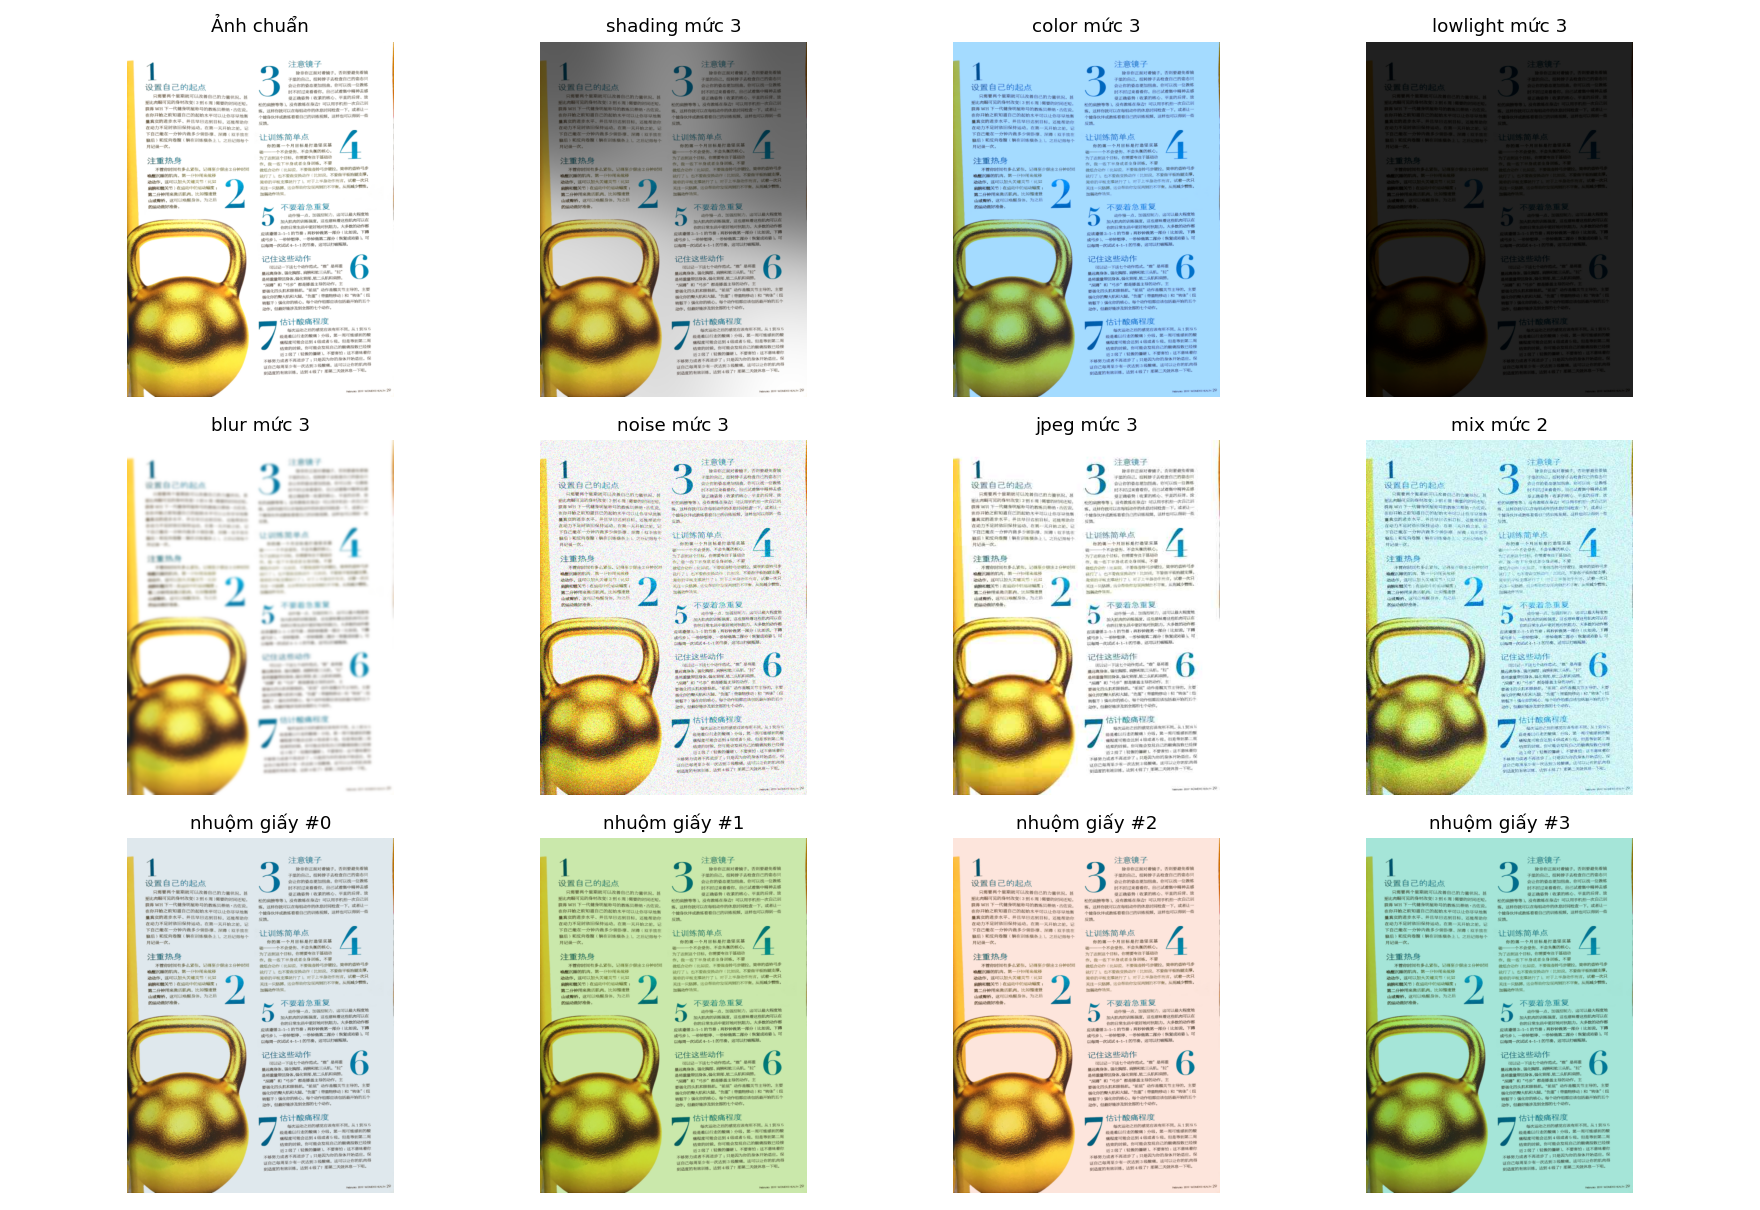

In [2]:
display(Image(filename=str(FIG / 'du_lieu_tong_hop.png')))


**Các run** (mỗi run train từ đầu, 8.000 vòng, batch 16, crop 192, AdamW lr 1e-3 + cosine, bf16, seed 0):


In [3]:
rows = []
for r in RUNS:
    cfg = json.loads((MOD / r / 'config.json').read_text('utf-8'))
    log = pd.DataFrame([json.loads(l) for l in (MOD / r / 'log.jsonl').read_text('utf-8').splitlines()])
    best = log.loc[log['val_score'].idxmax()]
    rows.append({'run': r, 'edge-w': cfg['edge_w'], 'paper-color': cfg['paper_color'], 'identity-p': cfg['identity_p'],
                 'tham số (M)': round(cfg['params'] / 1e6, 2), 'GPU': cfg['gpu'].replace('NVIDIA ', ''),
                 'vòng/giây (trung vị)': round(log['it_per_s'].median(), 1), 'thời gian train (phút)': round(log['sec'].sum() / 60, 1),
                 'best val PSNR': round(best['val_score'], 2), 'ở vòng': int(best['iter'])})
runs_tab = pd.DataFrame(rows).set_index('run')
runs_tab


,edge-w,paper-color,identity-p,tham số (M),GPU,vòng/giây (trung vị),thời gian train (phút),best val PSNR,ở vòng
run,,,,,,,,,
m4r_baseline,0.0,0.0,0.0,6.82,A100-SXM4-40GB,11.8,13.4,22.40,8000
m5a_edge,1.0,0.0,0.0,6.82,A100-SXM4-40GB,11.5,12.2,22.61,8000
m5b_color,0.0,0.2,0.0,6.82,A100-SXM4-40GB,11.8,11.9,22.42,8000
m5c_identity,0.0,0.0,0.1,6.82,A100-SXM4-40GB,12.0,18.1,22.51,7500
m5_all,1.0,0.2,0.1,6.82,A100-SXM4-40GB,11.4,12.3,22.51,8000


`m5c_identity` chậm hơn vì một phần thời gian nó chạy chung GPU với run khác (xem mục 6). Chạy riêng mỗi run mất khoảng 12 phút.


## 2. Quá trình train

Mỗi 500 vòng, log ghi loss train và PSNR trên tập val. Val gồm ảnh thật của từng nguồn (RealDAE, ESP32) và 200 patch tổng hợp cố định.
Checkpoint tốt nhất chọn theo **PSNR val trung bình trên ảnh thật**, không phải trên tập test.


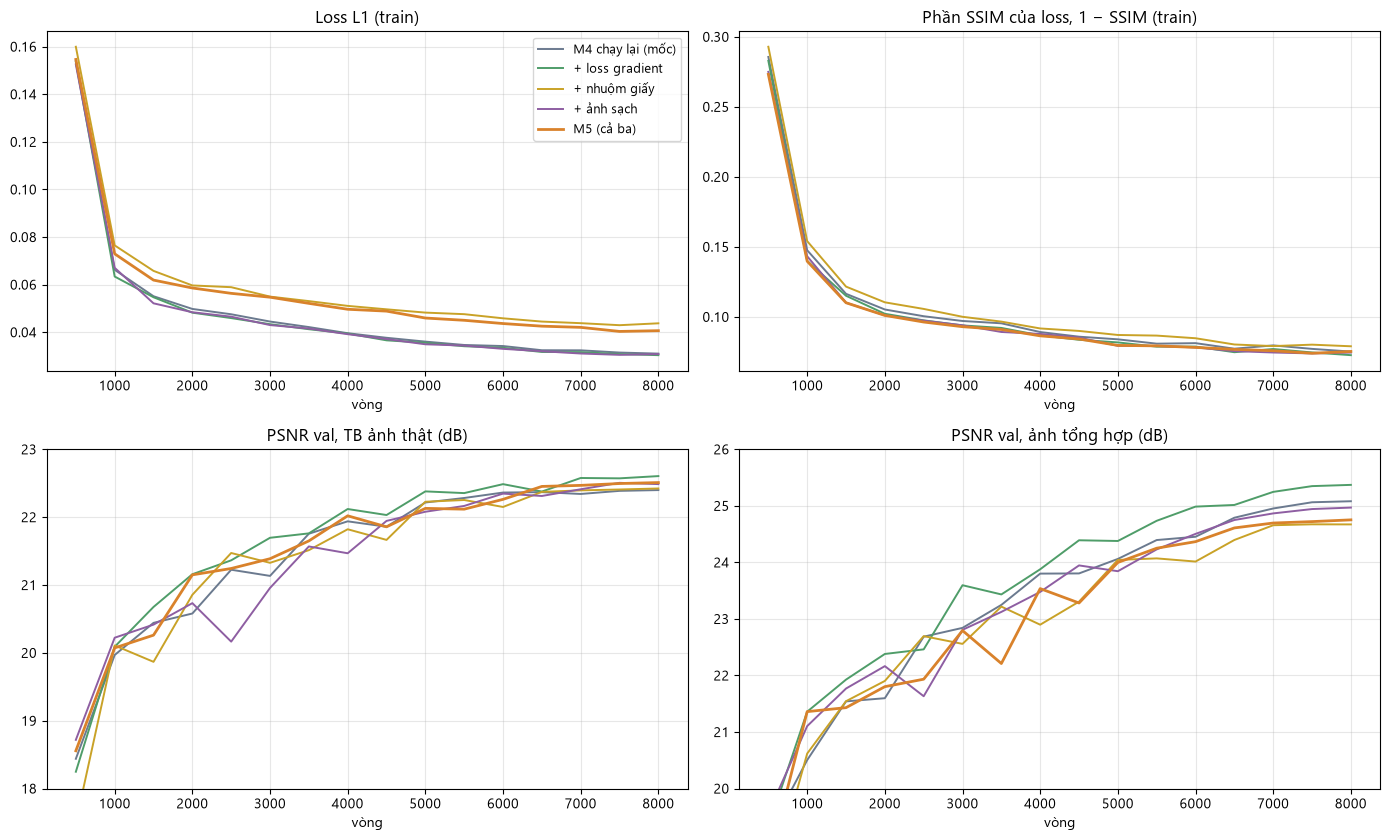

In [4]:
logs = {r: pd.DataFrame([json.loads(l) for l in (MOD / r / 'log.jsonl').read_text('utf-8').splitlines()]) for r in RUNS}
fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))
panels = [('train_l1', 'Loss L1 (train)'), ('train_ssim', 'Phần SSIM của loss, 1 − SSIM (train)'),
          ('val_score', 'PSNR val, TB ảnh thật (dB)'), ('val_synth_psnr', 'PSNR val, ảnh tổng hợp (dB)')]
for a, (col, title) in zip(ax.ravel(), panels):
    for r, df in logs.items():
        a.plot(df['iter'], df[col], label=LABEL[r], color=COLOR[r], lw=2 if r == 'm5_all' else 1.4)
    a.set_title(title); a.set_xlabel('vòng')
ax[0, 0].legend(fontsize=9)
ax[1, 0].set_ylim(18, 23); ax[1, 1].set_ylim(20, 26)
plt.tight_layout(); plt.savefig(OUT / 'retrain2_duong_cong_train.png', dpi=110); plt.show()


**Cách đọc hình.**

- Loss giảm đều ở cả năm run và PSNR val tăng đều, không có run nào phân kỳ.
- Loss L1 train **không so trực tiếp được giữa các run**: hai run có `--paper-color` (`+ nhuộm giấy` và `M5`) kết thúc ở khoảng 0,041, trong khi ba run còn lại ở khoảng 0,031.
  Lý do là ảnh chuẩn của chúng được nhuộm màu nên bài toán khác đi, không phải model học kém hơn: PSNR val của hai run này vẫn ngang các run còn lại.
- PSNR val dao động vài phần mười dB giữa các lần đo, nên thứ tự các run ở một vòng cụ thể không có ý nghĩa; chỉ đường xu hướng và giá trị cuối là đáng tin.

Hình dưới phóng to đoạn cuối (vòng 5.000–8.000) và vẽ loss gradient Sobel. Loss này chỉ có giá trị khác 0 ở `m5a_edge` và `m5_all` (cờ `--edge-w`); các run khác ghi 0, nên ba đường 0 nằm chồng lên nhau.


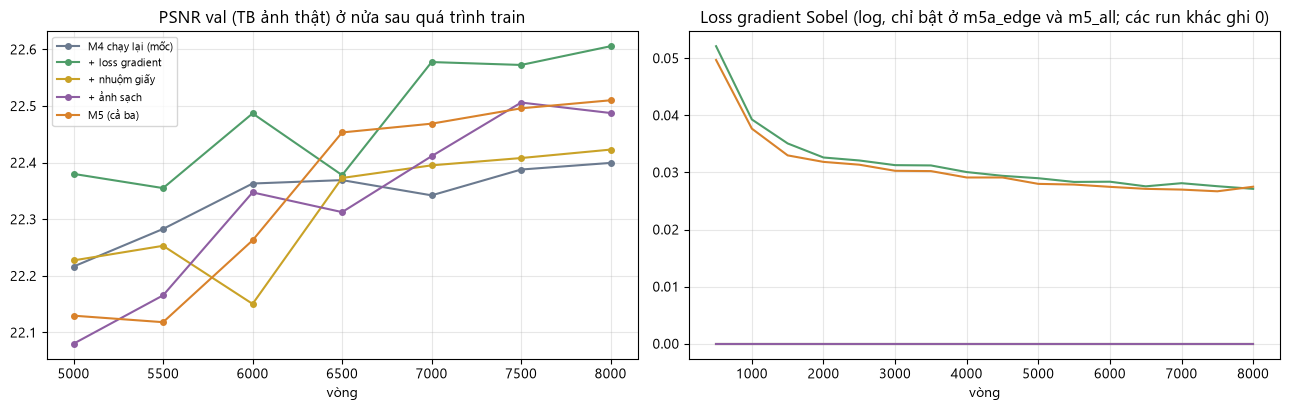

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for r, df in logs.items():
    d = df[df['iter'] >= 5000]
    ax[0].plot(d['iter'], d['val_score'], marker='o', ms=4, label=LABEL[r], color=COLOR[r])
    ax[1].plot(df['iter'], df['train_edge'], label=LABEL[r], color=COLOR[r])
ax[0].set_title('PSNR val (TB ảnh thật) ở nửa sau quá trình train'); ax[0].set_xlabel('vòng'); ax[0].legend(fontsize=8)
ax[1].set_title('Loss gradient Sobel (log, chỉ bật ở m5a_edge và m5_all; các run khác ghi 0)'); ax[1].set_xlabel('vòng')
plt.tight_layout(); plt.show()


PSNR trên tập val ở vòng cuối của từng run, theo nguồn (cột `ảnh vào` là PSNR của chính ảnh chưa xử lý, mốc để so):


In [6]:
last = pd.DataFrame({r: df.iloc[-1] for r, df in logs.items()}).T
tab = pd.DataFrame({
    'RealDAE (val)': last['val_realdae_psnr'], 'ESP32 (val)': last['val_esp32_psnr'], 'Tổng hợp (val)': last['val_synth_psnr'],
    'TB ảnh thật': last['val_score']}).astype(float).round(2)
tab.loc['ảnh vào (không xử lý)'] = [round(float(last['val_realdae_psnr_input'].iloc[0]), 2), round(float(last['val_esp32_psnr_input'].iloc[0]), 2),
                                    round(float(last['val_synth_psnr_input'].iloc[0]), 2), np.nan]
tab


,RealDAE (val),ESP32 (val),Tổng hợp (val),TB ảnh thật
m4r_baseline,26.66,18.13,25.08,22.40
m5a_edge,26.91,18.30,25.37,22.61
m5b_color,26.67,18.18,24.67,22.42
m5c_identity,26.81,18.17,24.97,22.49
m5_all,26.73,18.29,24.75,22.51
ảnh vào (không xử lý),12.08,6.16,8.94,NaN


Sau 8.000 vòng, năm run cách nhau tối đa khoảng 0,2 dB trên tập val: chưa đủ để nói cải tiến nào tốt hơn. Cần xem tập test (mục 3).


## 3. Kết quả trên tập test

`m4_prev` là M4 của đợt 1 (chạy trước đó, cấu hình giống `m4r_baseline`), chấm cùng lúc để kiểm tra mốc. Chỉ số: PSNR trên RGB, SSIM trên ảnh xám, LPIPS (thấp hơn là tốt hơn).


In [7]:
df = pd.read_csv(RES / 'summary.csv')
ORDER = ['m0_identity', 'm1_classic', 'm4_prev'] + RUNS
SETS = {'realdae': 'RealDAE test', 'synth': 'Tổng hợp (TB 21 ô)', 'docaligner': 'DocAligner', 'jung': 'Jung', 'esp32_pages': 'ESP32 10 trang'}
NAME = {'m0_identity': 'ảnh vào (không xử lý)', 'm1_classic': 'cổ điển (OpenCV)', 'm4_prev': 'M4 đợt 1', **LABEL}

def overall(s, metric):
    d = df[df['set'] == s]
    if s == 'synth':
        d = d[d['group'] != '.']
    return d.groupby('run')[metric].mean()

def table(metric):
    t = pd.DataFrame({SETS[s]: overall(s, metric) for s in SETS}).reindex(ORDER)
    t.index = [NAME[i] for i in t.index]
    return t

psnr = table('psnr')
print('PSNR (dB), cao hơn là tốt hơn; ô xanh là cao nhất mỗi cột')
psnr.round(2).style.highlight_max(axis=0, color='#c6efce')


PSNR (dB), cao hơn là tốt hơn; ô xanh là cao nhất mỗi cột


,RealDAE test,Tổng hợp (TB 21 ô),DocAligner,Jung,ESP32 10 trang
ảnh vào (không xử lý),12.400000,17.680000,13.960000,14.870000,nan
cổ điển (OpenCV),17.770000,14.970000,17.350000,18.360000,nan
M4 đợt 1,26.480000,24.750000,20.170000,16.910000,17.100000
M4 chạy lại (mốc),26.490000,24.540000,20.260000,16.900000,17.080000
+ loss gradient,26.630000,24.710000,20.270000,17.030000,17.230000
+ nhuộm giấy,26.490000,24.080000,20.230000,16.960000,17.080000
+ ảnh sạch,26.600000,24.970000,20.310000,16.920000,16.970000
M5 (cả ba),26.440000,24.590000,20.120000,16.990000,17.330000


In [8]:
print('SSIM, cao hơn là tốt hơn')
display(table('ssim').round(3).style.highlight_max(axis=0, color='#c6efce'))
print('LPIPS, thấp hơn là tốt hơn')
table('lpips').round(3).style.highlight_min(axis=0, color='#c6efce')


SSIM, cao hơn là tốt hơn


,RealDAE test,Tổng hợp (TB 21 ô),DocAligner,Jung,ESP32 10 trang
ảnh vào (không xử lý),0.858000,0.726000,0.790000,0.884000,nan
cổ điển (OpenCV),0.886000,0.753000,0.810000,0.806000,nan
M4 đợt 1,0.968000,0.912000,0.863000,0.851000,0.812000
M4 chạy lại (mốc),0.968000,0.910000,0.863000,0.851000,0.812000
+ loss gradient,0.967000,0.913000,0.864000,0.856000,0.814000
+ nhuộm giấy,0.967000,0.906000,0.863000,0.855000,0.812000
+ ảnh sạch,0.969000,0.910000,0.865000,0.851000,0.812000
M5 (cả ba),0.968000,0.910000,0.863000,0.856000,0.815000


LPIPS, thấp hơn là tốt hơn


,RealDAE test,Tổng hợp (TB 21 ô),DocAligner,Jung,ESP32 10 trang
ảnh vào (không xử lý),0.216000,0.261000,0.225000,0.112000,nan
cổ điển (OpenCV),0.177000,0.292000,0.186000,0.151000,nan
M4 đợt 1,0.050000,0.125000,0.130000,0.111000,nan
M4 chạy lại (mốc),0.050000,0.127000,0.129000,0.110000,nan
+ loss gradient,0.050000,0.124000,0.129000,0.104000,nan
+ nhuộm giấy,0.050000,0.131000,0.133000,0.108000,nan
+ ảnh sạch,0.049000,0.127000,0.129000,0.107000,nan
M5 (cả ba),0.048000,0.126000,0.133000,0.107000,nan


Biểu đồ cột PSNR từng tập (xám: không học; xanh dương: M4; các màu còn lại: bản M5). Trục tung cắt từ dưới để thấy được chênh lệch nhỏ.


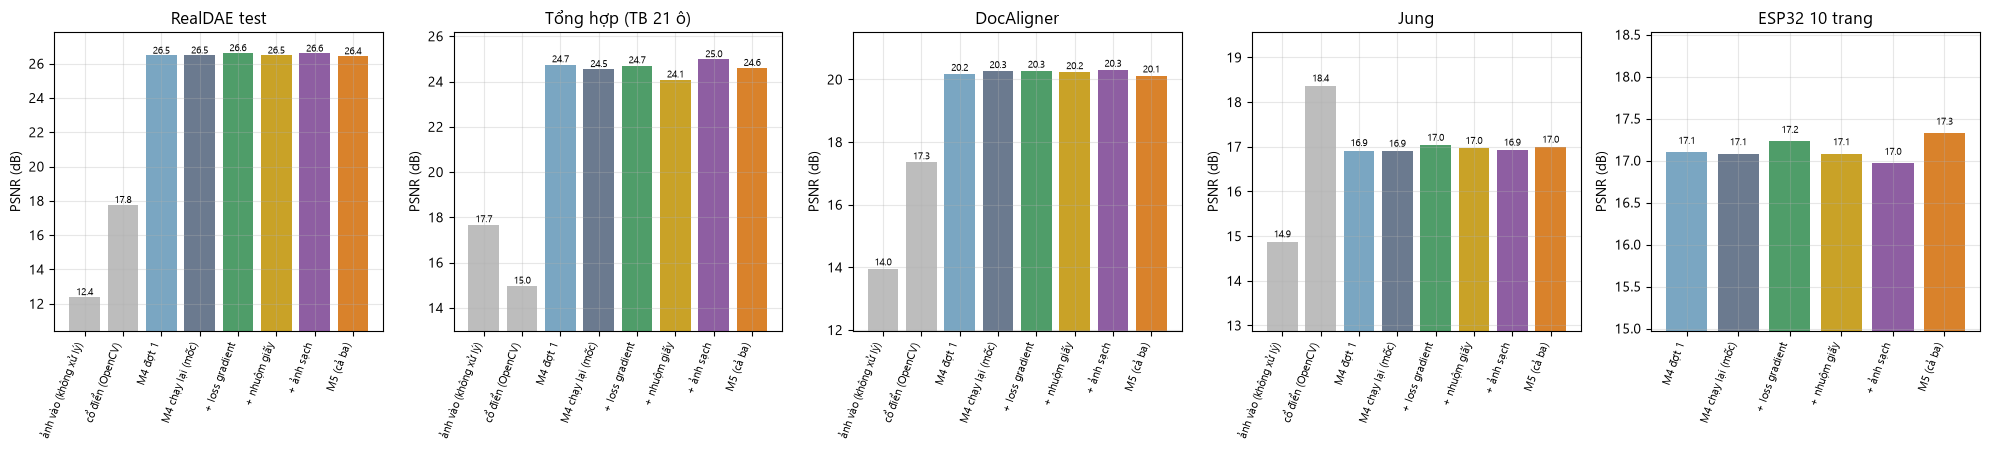

In [9]:
cols = list(psnr.columns)
fig, ax = plt.subplots(1, len(cols), figsize=(4.0 * len(cols), 4.6))
keys = list(psnr.index)
colors = ['#bdbdbd', '#bdbdbd', '#7aa6c2'] + [COLOR[r] for r in RUNS]
for a, c in zip(ax, cols):
    v = psnr[c].values
    sel = np.arange(len(v)) if c != 'ESP32 10 trang' else np.arange(2, len(v))
    a.bar(range(len(sel)), v[sel], color=[colors[i] for i in sel])
    a.set_xticks(range(len(sel))); a.set_xticklabels([keys[i] for i in sel], rotation=70, ha='right', fontsize=8)
    lo = np.nanmin(v[sel]); a.set_ylim(lo - 2 if c != 'RealDAE test' else lo - 2, np.nanmax(v[sel]) + 1.2)
    for k, i in enumerate(sel): a.text(k, v[i] + 0.1, f'{v[i]:.1f}', ha='center', fontsize=7)
    a.set_title(c); a.set_ylabel('PSNR (dB)')
plt.tight_layout(); plt.savefig(OUT / 'retrain2_psnr_theo_tap.png', dpi=110); plt.show()


**Lưu ý khi đọc:**

- **Jung:** phương pháp cổ điển đứng đầu (18,4 dB) vì ảnh chuẩn của Jung là ảnh chụp dưới ánh sáng đều (nền giấy xám nhạt), còn model cho nền trắng tinh kiểu scan.
  PSNR ở tập này chủ yếu đo lệch tông màu chứ không đo khả năng khử bóng; phân tích kỹ ở `reports/results/jung/SUMMARY.md`.
- **ESP32:** không có hai cột đầu vì ảnh ESP32 chưa nắn không so được với scan bằng PSNR trên cả trang (chỉ chấm các phiên bản đã qua model).
- **Cả 5 tập:** mọi bản M5 cách M4 dưới 0,3 dB (xem bảng ablation ở mục 5), cùng cỡ với nhiễu seed.

### 3.1 Tập tổng hợp theo từng loại suy biến

Mỗi ô là PSNR trung bình 3 mức. Biểu đồ nhiệt: mức tăng so với ảnh vào (xanh là model làm tốt hơn ảnh vào, đỏ là làm xấu hơn).


,ảnh vào (không xử lý),cổ điển (OpenCV),M4 đợt 1,M4 chạy lại (mốc),+ loss gradient,+ nhuộm giấy,+ ảnh sạch,M5 (cả ba)
loai,,,,,,,,
blur,22.320000,14.640000,21.830000,21.890000,21.930000,21.830000,21.960000,22.090000
color,20.520000,15.760000,27.070000,26.660000,26.690000,26.020000,27.470000,26.360000
jpeg,29.650000,15.460000,26.740000,26.430000,26.520000,25.990000,27.630000,27.340000
lowlight,4.510000,16.010000,23.900000,23.820000,24.230000,23.190000,23.910000,23.350000
mix,9.500000,12.890000,20.880000,20.830000,20.840000,20.400000,20.780000,20.390000
noise,23.540000,14.240000,27.790000,27.360000,27.700000,26.860000,27.890000,28.060000
shading,13.720000,15.790000,25.050000,24.770000,25.030000,24.250000,25.170000,24.550000


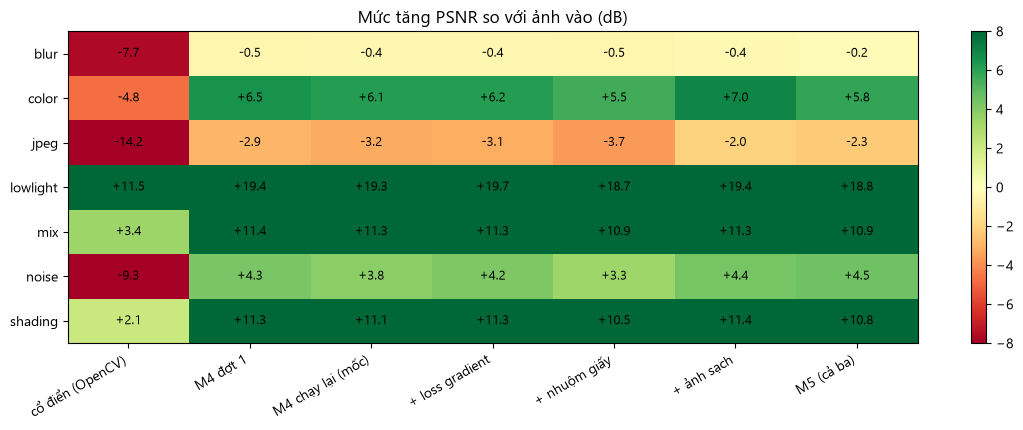

In [10]:
s = df[(df['set'] == 'synth') & (df['group'] != '.')].copy()
s['loai'] = s['group'].str.split('/').str[0]
by = s.pivot_table(index='loai', columns='run', values='psnr').reindex(columns=ORDER)
by.columns = [NAME[c] for c in by.columns]
display(by.round(2).style.highlight_max(axis=1, color='#c6efce'))

gain = by.sub(by['ảnh vào (không xử lý)'], axis=0).drop(columns=['ảnh vào (không xử lý)'])
fig, a = plt.subplots(figsize=(11.5, 4.4))
im = a.imshow(gain.values, cmap='RdYlGn', vmin=-8, vmax=8, aspect='auto'); a.grid(False)
a.set_xticks(range(gain.shape[1])); a.set_xticklabels(gain.columns, rotation=30, ha='right'); a.set_yticks(range(gain.shape[0])); a.set_yticklabels(gain.index)
for i in range(gain.shape[0]):
    for j in range(gain.shape[1]): a.text(j, i, f'{gain.values[i, j]:+.1f}', ha='center', va='center', fontsize=9)
a.set_title('Mức tăng PSNR so với ảnh vào (dB)'); plt.colorbar(im, ax=a); plt.tight_layout()
plt.savefig(OUT / 'retrain2_synth_theo_loai.png', dpi=110); plt.show()


Mọi model vẫn **thấp hơn ảnh vào** ở hai loại gần như không hỏng: `blur` (ảnh vào 22,3 dB) và `jpeg` (29,7 dB). Đây là điểm yếu "model làm xấu ảnh vốn đã tốt" mà `--identity-p` nhắm tới; phép thử riêng ở mục 4.1 cho thấy nó có giảm bớt hay không.


## 4. Ba phép thử riêng cho ba điểm yếu

### 4.1 Ảnh vốn đã sạch (`--identity-p`)

Đưa 60 ảnh scan sạch vào model (ảnh vào = ảnh chuẩn). Một model lý tưởng trả ảnh y hệt (PSNR vô hạn). PSNR của ảnh ra so với chính ảnh vào càng cao thì model càng ít làm hỏng ảnh tốt.


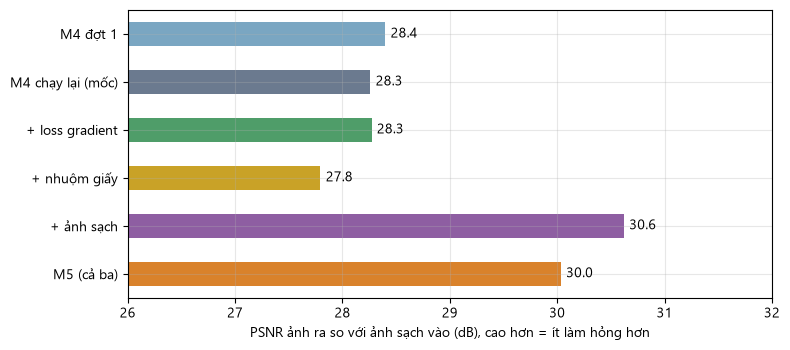

,PSNR (dB)
M4 đợt 1,28.40
M4 chạy lại (mốc),28.26
+ loss gradient,28.27
+ nhuộm giấy,27.79
+ ảnh sạch,30.62
M5 (cả ba),30.03


In [11]:
ci = df[(df['set'] == 'clean_identity') & df['run'].isin(['m4_prev'] + RUNS)].set_index('run')['psnr'].reindex(['m4_prev'] + RUNS)
ci.index = [NAME[i] for i in ci.index]
ax = ci.plot.barh(figsize=(8, 3.6), color=['#7aa6c2'] + [COLOR[r] for r in RUNS]); ax.invert_yaxis()
ax.set_xlabel('PSNR ảnh ra so với ảnh sạch vào (dB), cao hơn = ít làm hỏng hơn'); ax.set_xlim(26, 32)
for i, v in enumerate(ci.values): ax.text(v + 0.05, i, f'{v:.1f}', va='center')
plt.tight_layout(); plt.show()
ci.round(2).to_frame('PSNR (dB)')


### 4.2 Trang nền màu (`--paper-color`)

DocAligner có 3 trang nền màu chủ ý (ảnh 26_1, 26_2, 8_2) mà M4 tẩy trắng. Ngoài ra lấy 20 ảnh DocAligner mà M4 làm tệ nhất so với ảnh vào.
**Chỉ có 3 ảnh nền màu**, nên đây là phép thử rất nhỏ; xem như gợi ý, không phải kết luận.


In [12]:
def per_image(run):
    g = json.loads((RES / f'{run}__docaligner.json').read_text('utf-8'))['groups']
    return {im['name']: im['psnr'] for v in g.values() for im in v['images']}

dc = {r: per_image(r) for r in ['m0_identity', 'm1_classic', 'm4_prev'] + RUNS}
bad3 = ['26_1.png', '26_2.png', '8_2.png']
worst20 = sorted(dc['m4_prev'], key=lambda k: dc['m4_prev'][k] - dc['m0_identity'][k])[:20]
t2 = pd.DataFrame({NAME[r]: {'3 ảnh nền màu': np.mean([v[k] for k in bad3]), '20 ảnh M4 làm tệ nhất': np.mean([v[k] for k in worst20]),
                              'cả 130 ảnh': np.mean(list(v.values()))} for r, v in dc.items()}).T
t2.round(2).style.highlight_max(axis=0, color='#c6efce')


,3 ảnh nền màu,20 ảnh M4 làm tệ nhất,cả 130 ảnh
ảnh vào (không xử lý),16.690000,16.270000,13.960000
cổ điển (OpenCV),9.140000,12.960000,17.350000
M4 đợt 1,11.200000,16.400000,20.170000
M4 chạy lại (mốc),11.420000,16.440000,20.260000
+ loss gradient,11.180000,16.380000,20.270000
+ nhuộm giấy,11.630000,16.490000,20.230000
+ ảnh sạch,11.440000,16.470000,20.310000
M5 (cả ba),13.720000,16.880000,20.120000


### 4.3 Dấu tiếng Việt (`--edge-w`): CER bằng VietOCR

Cắt từng dòng chữ của 10 trang ESP32 test (317 dòng) từ ảnh đã nâng, cho **VietOCR bản gốc (chưa fine-tune)** đọc, tính tỉ lệ ký tự sai (CER).
"CER bỏ dấu" là CER sau khi xóa dấu thanh và dấu mũ ở cả nhãn lẫn kết quả; hiệu giữa hai số là phần lỗi chỉ do dấu.
`raw` là ảnh ESP32 chưa xử lý, `scan` là bản scan sạch (giới hạn trên).


,CER,CER bỏ dấu,lỗi riêng do dấu
ảnh ESP32 gốc,0.209000,0.170000,0.038000
bản scan (giới hạn trên),0.028000,0.026000,0.002000
M4 đợt 1,0.137000,0.087000,0.050000
M4 chạy lại (mốc),0.136000,0.087000,0.048000
+ loss gradient,0.136000,0.085000,0.050000
+ nhuộm giấy,0.135000,0.087000,0.048000
+ ảnh sạch,0.136000,0.086000,0.050000
M5 (cả ba),0.137000,0.086000,0.051000


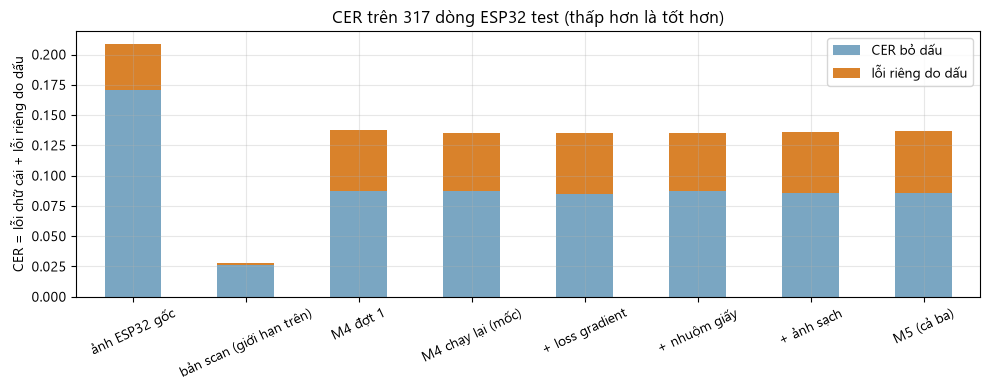

In [13]:
cer = pd.read_csv(RES / 'cer_esp32.csv').set_index('phiên bản').reindex(['raw', 'scan', 'm4_prev'] + RUNS)
cer.index = ['ảnh ESP32 gốc', 'bản scan (giới hạn trên)', 'M4 đợt 1'] + [LABEL[r] for r in RUNS]
display(cer.round(3).style.highlight_min(axis=0, subset=pd.IndexSlice[cer.index[2:], :], color='#c6efce'))
ax = cer[['CER bỏ dấu', 'lỗi riêng do dấu']].plot.bar(stacked=True, figsize=(10, 4), color=['#7aa6c2', '#d9822b'], rot=25)
ax.set_ylabel('CER = lỗi chữ cái + lỗi riêng do dấu'); ax.set_title('CER trên 317 dòng ESP32 test (thấp hơn là tốt hơn)')
plt.tight_layout(); plt.show()


Thanh xếp chồng tách CER thành lỗi chữ cái (xanh) và lỗi riêng do dấu (cam). Mọi model giảm lỗi chữ cái rất nhiều so với ảnh gốc, nhưng phần cam **không giảm**, thậm chí cao hơn ảnh gốc.


## 5. Tác động của từng cải tiến (ablation) và ảnh trước/sau

Chênh PSNR so với `m4r_baseline` (cùng cấu hình, cùng seed). Chỉ ô nào chênh lớn hơn ~0,3 dB mới có thể coi là khác biệt thật.


In [14]:
abl = pd.read_csv(RES / 'ablation_delta.csv').set_index('run')
abl.index = [LABEL[i] for i in abl.index]
print('Chênh PSNR so với M4 chạy lại (dB)')
abl.round(2).style.background_gradient(cmap='RdYlGn', vmin=-0.6, vmax=0.6).format('{:+.2f}')


Chênh PSNR so với M4 chạy lại (dB)


,RealDAE test,Tổng hợp (TB các ô),DocAligner,Jung,ESP32 10 trang
+ loss gradient,+0.13,+0.17,+0.01,+0.13,+0.15
+ nhuộm giấy,-0.00,-0.46,-0.03,+0.06,+0.00
+ ảnh sạch,+0.11,+0.44,+0.04,+0.02,-0.12
M5 (cả ba),-0.05,+0.05,-0.14,+0.09,+0.24


**Ảnh trước/sau** (hình do notebook Colab vẽ): các cột là ảnh vào, M4, M5, ảnh chuẩn; các hàng là trang nền màu (DocAligner 26_2), trang điển hình, bóng đổ (Jung),
ảnh chỉ mờ (tổng hợp) và trang ESP32.


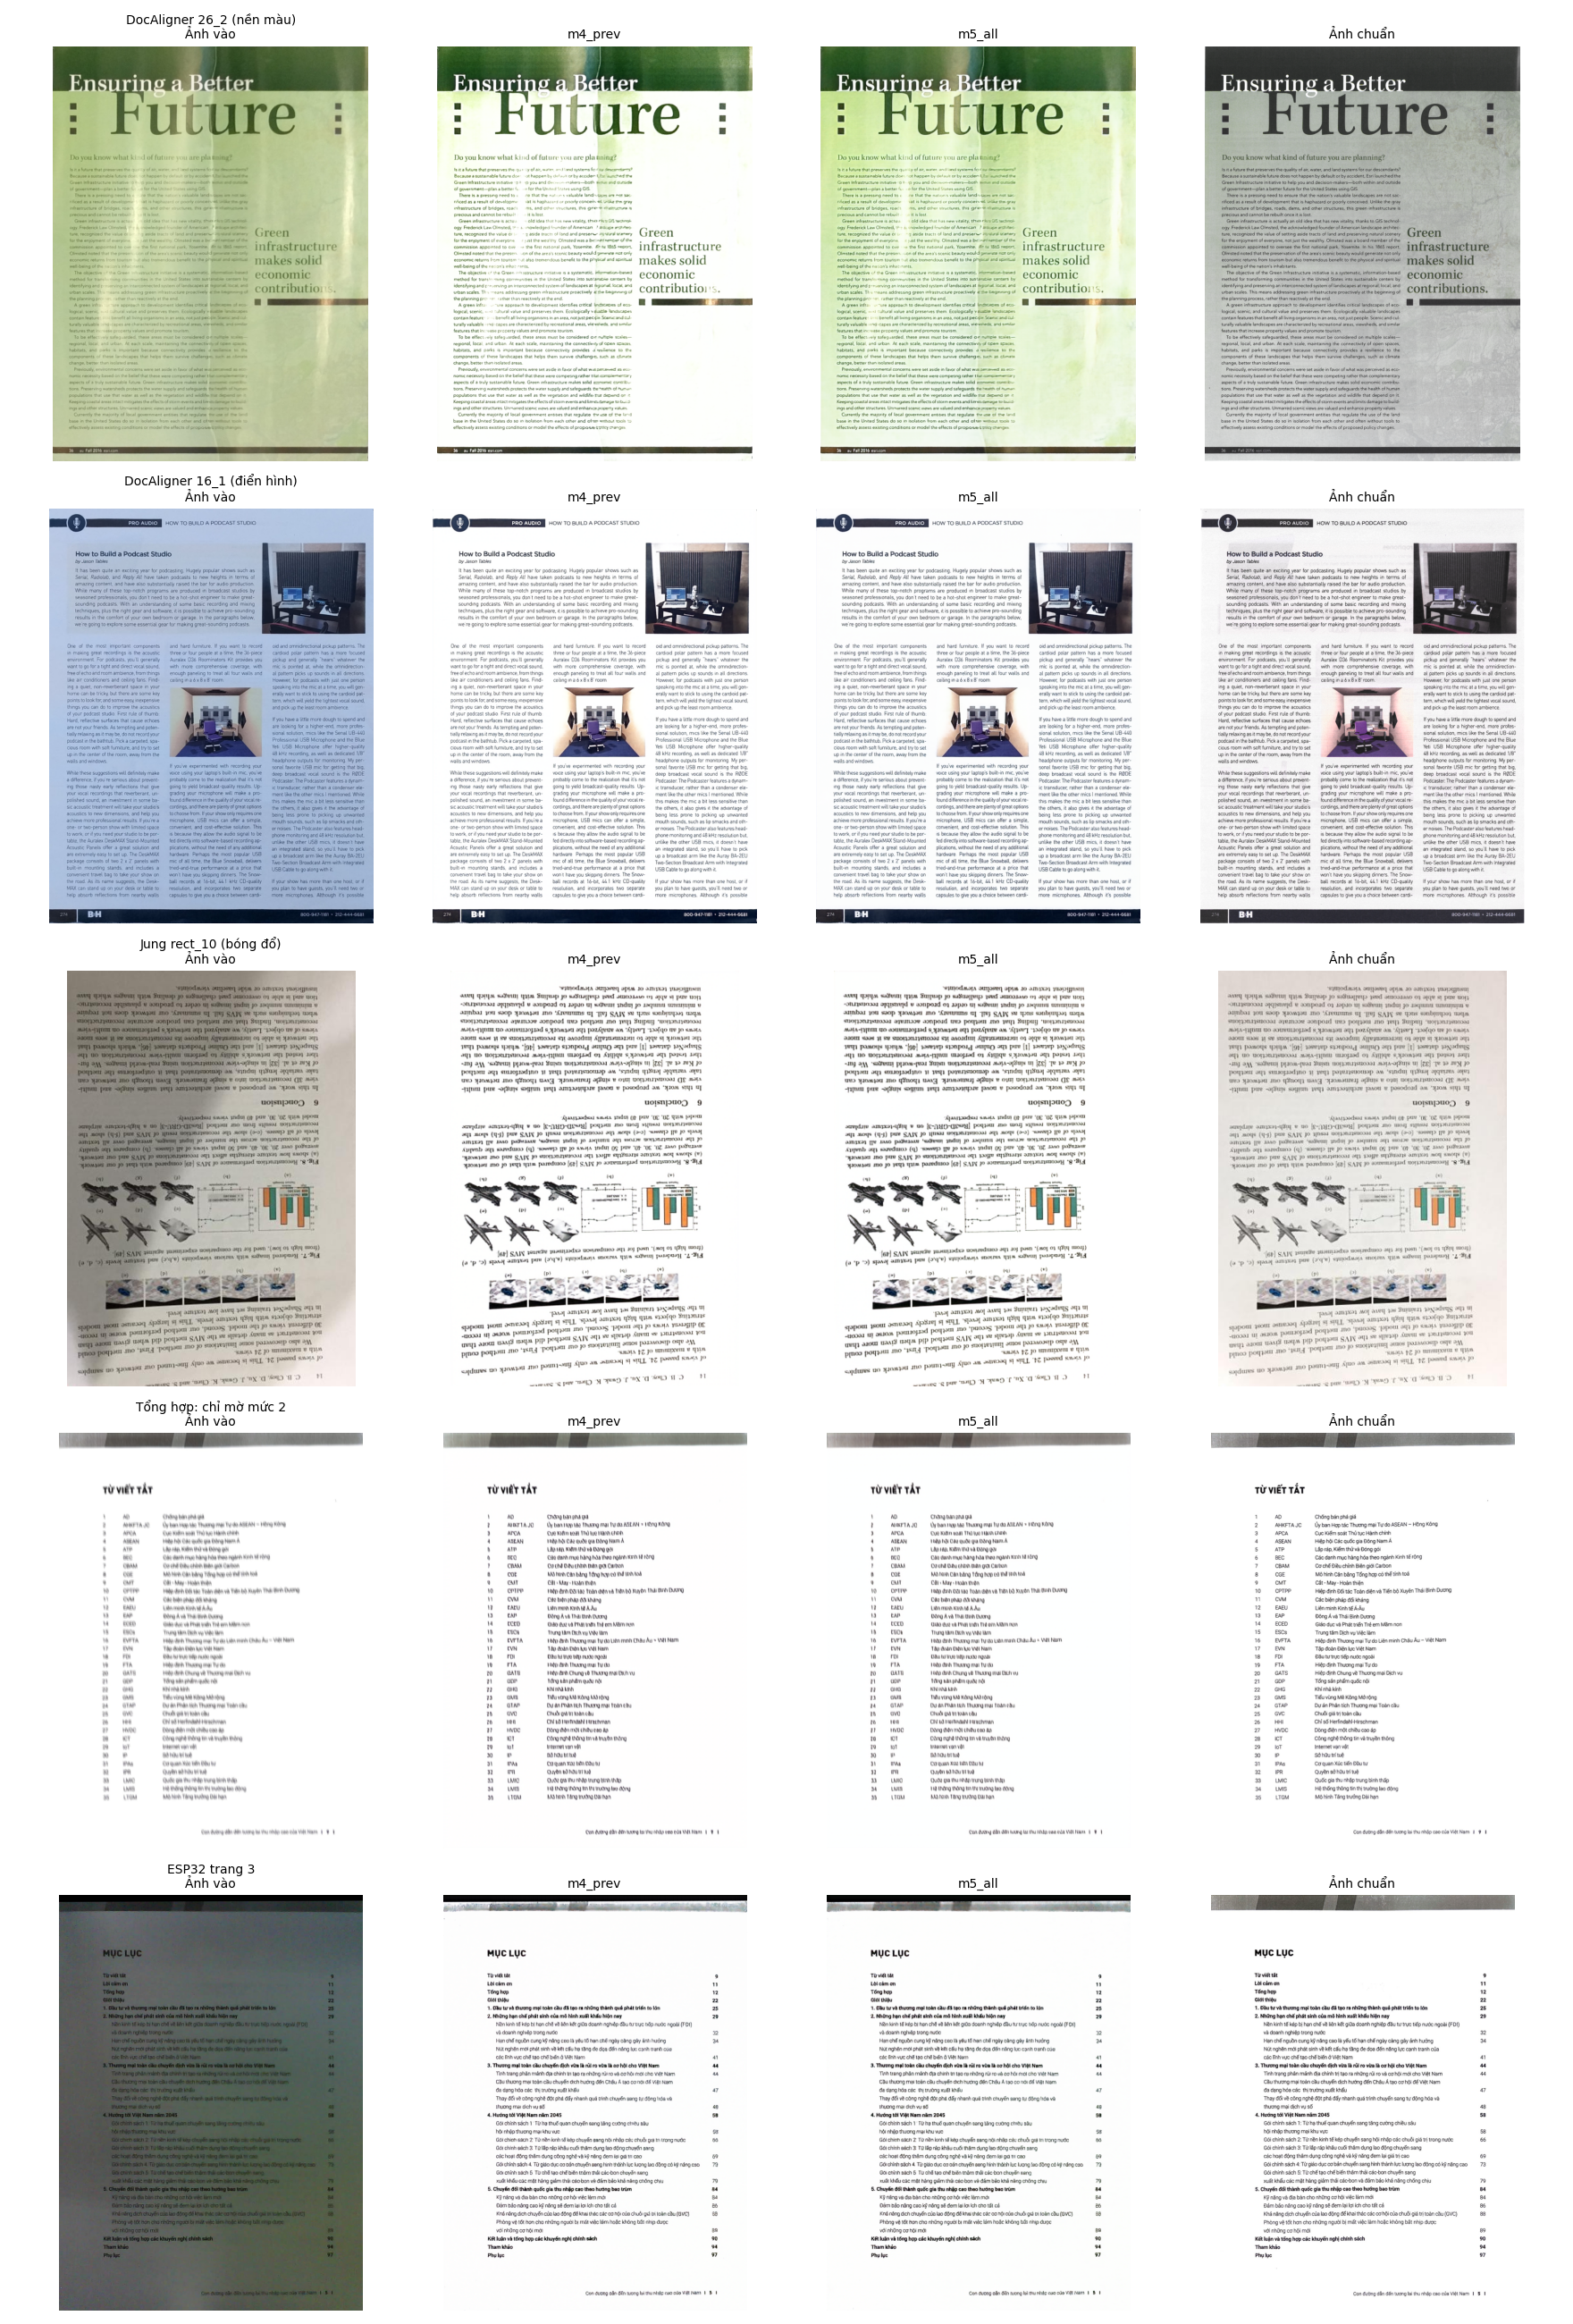

In [15]:
display(Image(filename=str(FIG / 'truoc_sau.png')))


**Nhận xét hình (nhìn bằng mắt, chỉ 5 ảnh nên chỉ mang tính minh họa):**

- **Hàng 1, trang nền xanh:** M4 tẩy phần lớn nền xanh về trắng, còn M5 giữ được màu xanh nhiều hơn. Khớp với kết quả ở mục 4.2 (M5 khá hơn mốc trên 3 ảnh nền màu). Ảnh chuẩn của trang này có nền xám xanh tối hơn cả hai model.
- **Hàng 2, 3, 5:** M4 và M5 gần như không phân biệt được bằng mắt, đúng với chênh PSNR dưới 0,3 dB.
- **Hàng 3 (Jung):** model cho nền trắng tinh, ảnh chuẩn có nền giấy xám nhạt; đây là nguyên nhân PSNR thấp trên tập Jung (mục 3).
- **Hàng 4 (chỉ mờ):** ảnh ra không rõ nét hơn ảnh vào, phù hợp với việc mọi model xấu hơn ảnh vào ở loại `blur`.


## 6. Kết luận


In [16]:
d = abl.loc[LABEL['m5_all']]
print('M5 (cả ba cải tiến) so với M4 chạy lại, PSNR (dB):')
for c, v in d.items():
    nhan = 'tốt hơn' if v > 0.3 else 'kém hơn' if v < -0.3 else 'ngang nhau (trong nhiễu seed)'
    print(f'  {c:22s} {v:+.2f}  {nhan}')
print()
ci2 = ci.copy(); base = ci2[LABEL['m4r_baseline']]
print(f'Ảnh sạch: M4 chạy lại {base:.2f} dB; +ảnh sạch {ci2[LABEL["m5c_identity"]]:.2f}; M5 {ci2[LABEL["m5_all"]]:.2f}')
dau = cer['lỗi riêng do dấu']
print(f'Lỗi riêng do dấu (CER): ảnh gốc {dau.iloc[0]:.3f}; M4 chạy lại {dau[LABEL["m4r_baseline"]]:.3f}; +loss gradient {dau[LABEL["m5a_edge"]]:.3f}; M5 {dau[LABEL["m5_all"]]:.3f}')


M5 (cả ba cải tiến) so với M4 chạy lại, PSNR (dB):
  RealDAE test           -0.05  ngang nhau (trong nhiễu seed)
  Tổng hợp (TB các ô)    +0.05  ngang nhau (trong nhiễu seed)
  DocAligner             -0.14  ngang nhau (trong nhiễu seed)
  Jung                   +0.09  ngang nhau (trong nhiễu seed)
  ESP32 10 trang         +0.24  ngang nhau (trong nhiễu seed)

Ảnh sạch: M4 chạy lại 28.26 dB; +ảnh sạch 30.62; M5 30.03
Lỗi riêng do dấu (CER): ảnh gốc 0.038; M4 chạy lại 0.049; +loss gradient 0.051; M5 0.051


**Tóm tắt (một seed mỗi cấu hình; chỉ dựa trên số đo ở trên):**

1. **M5 không tốt hơn M4 đo được.** Trên 5 tập test, mọi chênh PSNR giữa M5 và M4 chạy lại đều dưới 0,3 dB, tức trong nhiễu seed. Không có run nào "thắng" rõ rệt ở các tập này.
2. **Điểm yếu "ảnh sạch bị hỏng": cải thiện rõ.** Hai run có `--identity-p` giữ ảnh sạch tốt hơn mốc khoảng 2 dB (mục 4.1). Model vẫn chưa trả ảnh nguyên vẹn.
3. **Điểm yếu "nền màu": chưa kết luận được.** Chỉ run gộp cả ba cải tiến khá hơn mốc, trên 3 ảnh. `--paper-color` dùng riêng không giúp, và làm giảm PSNR tập tổng hợp (mục 4.2 và bảng ablation). Mọi model vẫn kém ảnh vào trên 3 ảnh này. Cần thêm dữ liệu nền màu để kiểm tra đàng hoàng.
4. **Điểm yếu "dấu tiếng Việt": không cải thiện.** Lỗi riêng do dấu của mọi model (0,048–0,051) cao hơn ảnh gốc (0,038). Loss gradient không sửa được. Cả sáu phiên bản chỉ lệch nhau ≤ 0,002 CER (mục 4.3).
5. **Hướng tiếp theo cho dấu:** thử loss theo vùng chữ hoặc loss OCR (VietOCR đóng băng), tăng độ phân giải xử lý, hoặc fine-tune VietOCR trên ảnh đã nâng. Model lớn (M4-L, đợt 1) đạt PSNR tập tổng hợp cao hơn mọi bản cỡ nhỏ nhưng không giúp ESP32.

Nên ghi nhận trong báo cáo: đây là **kết quả âm cho ba cải tiến**, trừ `--identity-p`. Chúng không làm hỏng model, nhưng cũng không đem lại lợi ích đo được ở quy mô này.


## 7. Sự cố khi chạy trên Colab và cách xử lý

- **Hết bộ nhớ GPU (CUDA OOM):** 5 run song song trên A100 40 GB; 4 run chết ở khoảng vòng 500 (log giữ ở `models/retrain2/_oom_aborted/`). Chạy lại 4 run từ đầu, lần lượt, với `PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True`; các tham số khác giữ nguyên.
  Notebook Colab đã sửa: tối đa 3 run chạy cùng lúc.
- **Cầu nối Colab không mở được notebook người dùng đã mở**, nên các ô chạy trong một tab riêng và không lưu được bản notebook đã chạy. Đó là lý do có notebook này.
- **Cài `vietocr==0.3.13` lỗi trên Python 3.13** (ghim `pillow==10.2.0`): cài `--no-deps` rồi cài các gói cần dùng. Điều này đã đổi bộ thư viện so với lần đo CER trước; CER của ảnh gốc (0,209) và bản scan (0,028) vẫn hợp lý.
- **Lỗi bảng thống kê dữ liệu** trong ô 7 của notebook Colab (3 cột nhưng 4 giá trị): đã sửa trong `notebooks/make_retrain_notebook.py`.
- Chi tiết, thời gian từng run và danh sách tệp: `docs/NHAT_KY_TRAIN_LAI.md`, mục 9.
